In [17]:
# import data sets 
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np


dataset_1 = np.loadtxt('datafile-exp.txt')
dataset_2 = np.loadtxt('datafile-expgaus.txt')


print(dataset_1)
print(dataset_2)

[1.0323898  6.62226715 2.89684053 ... 1.11462491 0.53856421 1.02922886]
[0.97160028 0.46505173 2.24309867 ... 5.25881333 5.53710739 5.31947016]


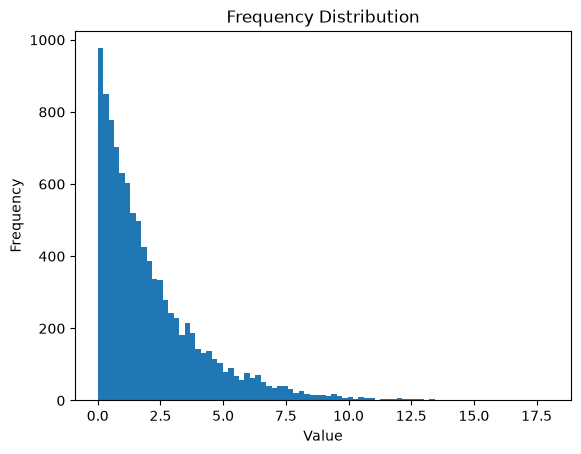

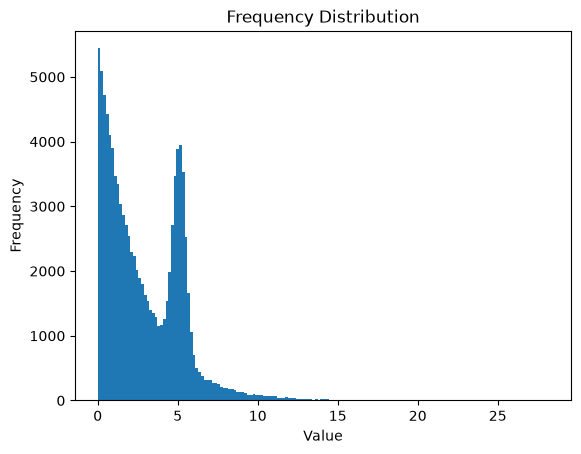

In [18]:
# plot data set 1 and data set 2 

plt.hist(dataset_1, bins='auto')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Frequency Distribution')
plt.show()

plt.hist(dataset_2, bins='auto')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Frequency Distribution')
plt.show()

In [19]:
from iminuit import cost, Minuit
import scipy.stats


def exp_pdf(x, scale):
    return scipy.stats.expon.pdf(x, scale=scale)

# Define an unbinned negative log-likelihood
cost_exp = cost.UnbinnedNLL(dataset_1, exp_pdf)

# Initial estimate: for an exponential distribution, the mean is the scale parameter
scale0 = np.mean(dataset_1)

# Run the fit
m_exp = Minuit(cost_exp, scale0)
m_exp.migrad()
m_exp.hesse()

# Print out results
print(m_exp)
print('Fitted scale =', m_exp.values['scale'])

np.shape(m_exp.covariance)

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 3.532e+04                  │              Nfcn = 26               │
│ EDM = 6.8e-11 (Goal: 0.0002)     │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬─────

(1, 1)

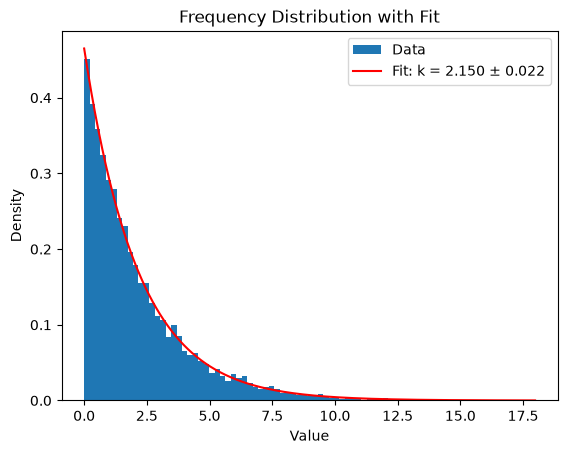

In [20]:
# plot the data set with the fit overlayed

x_fit1 = np.linspace(0, np.max(dataset_1), 1000)
y_fit2 = scipy.stats.expon.pdf(x_fit1, scale=m_exp.values['scale'])
k_err = np.sqrt(np.diag(m_exp.covariance))

plt.hist(dataset_1, bins='auto', density=True, label='Data')
# plot the fit with k and error stated as a label 
plt.plot(x_fit1, y_fit2, 'r-', label=f'Fit: k = {m_exp.values["scale"]:.3f} ± {k_err[0]:.3f}')
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Frequency Distribution with Fit')
plt.legend()
plt.show()



In [21]:

def expgaus_pdf(x, scale, mu, w):
    exp = scipy.stats.expon.pdf(x, scale=scale)
    gaus = scipy.stats.norm.pdf(x, loc=mu, scale=0.4)
    return w * exp + (1 - w) * gaus

cost_exp = cost.UnbinnedNLL(dataset_2, expgaus_pdf)

scale0 = np.mean(dataset_2)

m_exp = Minuit(cost_exp, scale=scale0, mu=5, w=0.5)
m_exp.limits['scale'] = (0, None)
m_exp.limits['w'] = (0, 1)

m_exp.migrad()
m_exp.hesse()

print(m_exp)



┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 3.883e+05                  │              Nfcn = 87               │
│ EDM = 5.22e-05 (Goal: 0.0002)    │            time = 0.5 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬─────

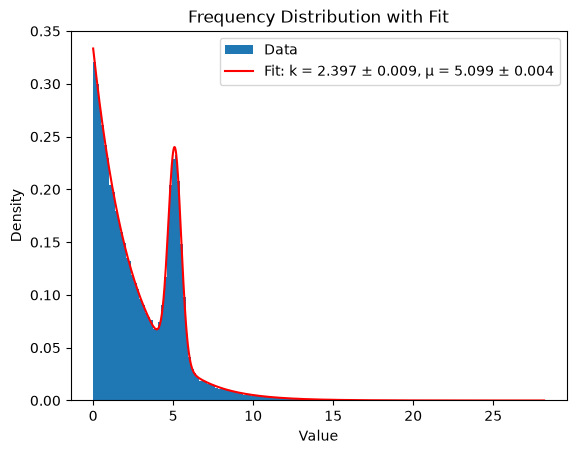

In [22]:
# overlay the fit on the histogram of dataset_2
x_fit2 = np.linspace(0, np.max(dataset_2), 1000)

y_fit2 = expgaus_pdf(x_fit2, scale=m_exp.values['scale'], mu=m_exp.values['mu'], w=m_exp.values['w'])

err_values = np.sqrt(np.diag(m_exp.covariance))
k_err = err_values[0]
mu_err = err_values[1]

plt.hist(dataset_2, bins='auto', density=True, label='Data')
plt.plot(
    x_fit2, y_fit2, 'r-',
    label=f'Fit: k = {m_exp.values["scale"]:.3f} ± {k_err:.3f}, '
          f'μ = {m_exp.values["mu"]:.3f} ± {mu_err:.3f}'
)
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Frequency Distribution with Fit')
plt.legend()
plt.show()


In [23]:
import emcee

def log_prob(theta):
    scale, mu, w = theta
    if scale <= 0 or not (0 < w < 1):
        return -np.inf
    val = -0.5 * cost_exp(scale, mu, w)
    return val if np.isfinite(val) else -np.inf

ndim, nwalkers = 3, 32
p0 = np.array(m_exp.values) + 1e-3 * np.random.randn(nwalkers, ndim)
p0[:, 2] = np.clip(p0[:, 2], 0.01, 0.99)

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob)
sampler.run_mcmc(p0, 1000, progress=True)
flat = sampler.get_chain(discard=100, thin=10, flat=True)

# compare with Hessian errors
print(flat.std(axis=0))
print(np.array(m_exp.errors))

100%|██████████| 1000/1000 [03:23<00:00,  4.91it/s]

[0.00900737 0.00382305 0.00158149]
[0.00904183 0.00384141 0.00157651]


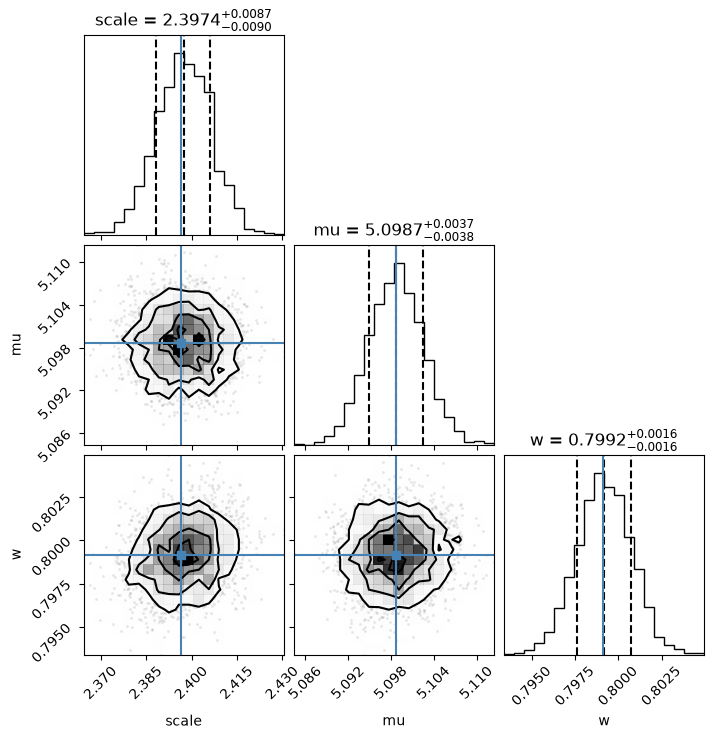

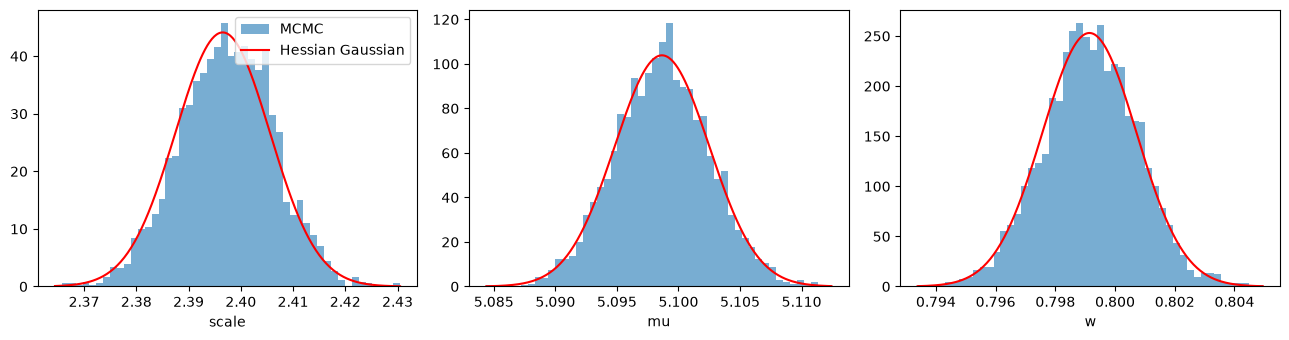

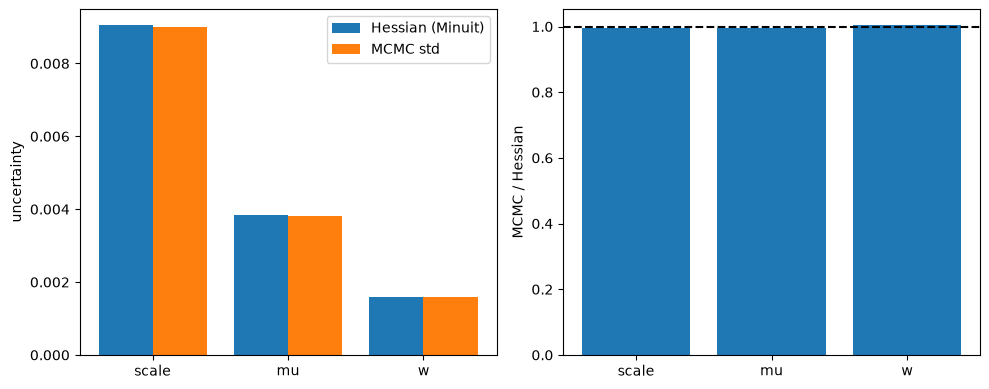

scale: Hessian 2.3965 ± 0.0090 | MCMC 2.3974 +0.0087 -0.0090 | ratio 1.00
mu: Hessian 5.0987 ± 0.0038 | MCMC 5.0987 +0.0037 -0.0038 | ratio 1.00
w: Hessian 0.7991 ± 0.0016 | MCMC 0.7992 +0.0016 -0.0016 | ratio 1.00


In [24]:
import corner
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

names = ["scale", "mu", "w"]
best = np.array(m_exp.values)
hess_err = np.array(m_exp.errors)
mcmc_err = flat.std(axis=0)

# 1. Posterior: corner plot (1D marginals + 2D contours)
fig = corner.corner(
    flat, labels=names, truths=best,
    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt=".4f",
)
plt.show()

# 2. 1D marginals with the Hessian Gaussian overlaid
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for i, name in enumerate(names):
    ax[i].hist(flat[:, i], bins=50, density=True, alpha=0.6, label="MCMC")
    g = np.linspace(flat[:, i].min(), flat[:, i].max(), 300)
    ax[i].plot(g, norm.pdf(g, best[i], hess_err[i]), "r", label="Hessian Gaussian")
    ax[i].set_xlabel(name)
ax[0].legend()
plt.tight_layout()
plt.show()

# 3. Error comparison
x = np.arange(3)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].bar(x - 0.2, hess_err, 0.4, label="Hessian (Minuit)")
ax[0].bar(x + 0.2, mcmc_err, 0.4, label="MCMC std")
ax[0].set_xticks(x); ax[0].set_xticklabels(names)
ax[0].set_ylabel("uncertainty"); ax[0].legend()

ax[1].bar(x, mcmc_err / hess_err)
ax[1].axhline(1, color="k", ls="--")
ax[1].set_xticks(x); ax[1].set_xticklabels(names)
ax[1].set_ylabel("MCMC / Hessian")
plt.tight_layout()
plt.show()

# numbers, including asymmetric 16/84 percentile errors
for i, name in enumerate(names):
    lo, med, hi = np.percentile(flat[:, i], [16, 50, 84])
    print(f"{name}: Hessian {best[i]:.4f} ± {hess_err[i]:.4f} | "
          f"MCMC {med:.4f} +{hi-med:.4f} -{med-lo:.4f} | ratio {mcmc_err[i]/hess_err[i]:.2f}")